---
authors:
  - name: Emma Pidduck
    url: https://www.linkedin.com/in/emmapidduck/
---

# Day 25 · Is this a map? — A slice through the sky over Romania

### #30DayMapChallenge 2026 · ECMWF IFS 9 km open data · Maps by Emma Pidduck

Two pictures of the **same moment** over Romania, made from ECMWF's **IFS 9 km open data**. The
first is a map anyone would call a map: looking *down* on the country, coloured by whether the air
is **rising or sinking**. The second takes the dashed line on that map and looks at the atmosphere
*edge-on* — a **vertical slice** from the ground up to 16 km, along 25°E. It has latitude across
the bottom and height up the side, coastlines nowhere in sight.

**So — is the second one a map?** It plots a real, continuous quantity over a real, located
plane through the Earth's atmosphere. It is exactly as much a map as the first; it just chose a
*vertical* plane instead of a horizontal one. That is the whole point of today's theme.

Self-contained: method, code, output, data licence and tools in one place, runnable on any
laptop with `pip`.

## Method

- Pull one field set from the **IFS** (ECMWF's physics-based forecast model) on pressure levels,
  at the full **0.1° (~9 km)** open-data resolution: **vertical velocity** `w` (ω, in Pa s⁻¹),
  plus wind (`u`, `v`), temperature `t` and specific humidity `q`, on 12 levels from 1000 to 100 hPa.
- **The map** — vertical velocity at **700 hPa** over Romania and the Carpathians, with the
  700 hPa flow as thin streamlines. ω is negative for rising air, so we plot **−ω** (red = up,
  blue = down) and convert to the friendlier **hPa per hour**. The dashed line marks where we slice.
- **The slice** — take a narrow band around **25°E** (24–26°E, averaged) and draw the
  atmosphere in the latitude–pressure plane: vertical motion (fill), **potential temperature**
  as isentropes (the stratification — flat where stable, bunched at fronts and the tropopause),
  a **cloud outline** where relative humidity ≥ 80 %, and the **jet core** (wind-speed contours).
- A note on names: at ~45°N this is the **mid-latitude** regime — the transverse circulation
  around the jet and travelling weather systems, *not* the tropical **Hadley cell** (that lives
  in the deep tropics). Same idea — air going up in one place and down in another — different
  latitude band.

**The quiet field.** Vertical motion is the quantity weather lives by — cloud, rain and storms
are all air going up — yet it is almost never drawn: it is a hundred times smaller than the
horizontal wind and easy to overlook. ECMWF's IFS open data publishes it (`pl: … u, v, w …`) on
every pressure level, on the same 0.1° grid as everything else in this book, so both pictures
below come straight from open data with nothing reconstructed.

## Licence & attribution

Access to ECMWF Open Data is governed by the **Creative Commons CC-BY-4.0** licence and the
associated [Terms of Use](https://apps.ecmwf.int/datasets/licences/general/).

> In applying this licence, ECMWF does not waive the privileges and immunities granted to it
> by virtue of its status as an intergovernmental organisation.

Attribute any map made from this data:
`Data: © 2026 ECMWF, CC-BY-4.0 · Source: www.ecmwf.int`. State modifications (here: nearest
0.1° grid, −ω converted to hPa/hr, a light spatial smoothing on the slice for legibility).

## Tools

| Tool | Role |
|---|---|
| [`ecmwf-opendata`](https://github.com/ecmwf/ecmwf-opendata) | retrieve **IFS** open data on pressure levels |
| [`earthkit-data`](https://earthkit-data.readthedocs.io) | read & handle the GRIB (modern ECMWF stack) |
| `cartopy` | the map projection, coastlines and borders |
| `matplotlib` | the vertical cross-section (latitude × pressure) |
| [`cmcrameri`](https://www.fabiocrameri.ch/colourmaps/) | `vik` — a perceptually-uniform, colourblind-safe **diverging** ramp (up ↔ down) |

Two gotchas baked in below: pass **`resol="0p1"`** for the 0.1° (~9 km) grid (the client defaults
to 0.25°); and the pressure-level set includes **`w`** — vertical velocity, published on every
level, the field this whole day rests on.

In [1]:
# Run once if needed (uncomment):
#!pip install ecmwf-opendata earthkit-data cfgrib xarray cartopy cmcrameri scipy matplotlib

In [2]:
import os, sys, io, contextlib, warnings
warnings.filterwarnings("ignore")
import numpy as np
import xarray as xr
import earthkit.data as ekd
from ecmwf.opendata import Client
import matplotlib.pyplot as plt
import matplotlib.cm as mcm
import matplotlib.image as mpimg
import matplotlib.patheffects as pe
from matplotlib.ticker import ScalarFormatter, NullFormatter
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cmcrameri import cm as cmc
try:
    from scipy.ndimage import gaussian_filter
except Exception:
    gaussian_filter = None

plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Avenir Next", "Helvetica Neue", "Arial", "DejaVu Sans"]
BG, INK, MUT, GRID = "#ffffff", "#222222", "#6b6b6b", "#b9c0c8"

@contextlib.contextmanager
def quiet():
    """Silence the open-data banner + download progress bars. Real errors still raise."""
    py = sys.stderr; sys.stderr = io.StringIO()
    try:
        saved = os.dup(2); dn = os.open(os.devnull, os.O_WRONLY); os.dup2(dn, 2)
    except Exception:
        saved = None
    try:
        yield
    finally:
        sys.stderr = py
        if saved is not None:
            os.dup2(saved, 2); os.close(saved); os.close(dn)

### Configuration

`DATE = 0` pulls **today's** 00 UTC IFS run, so re-running on **25 November 2026** produces that
day's atmosphere with no edits. The slice is the meridian **25°E**, from 40°N to 52°N.

In [3]:
DATE, TIME, STEP = 0, 0, 0                       # today 00Z IFS, analysis step
LEVELS = [1000, 925, 850, 700, 600, 500, 400, 300, 250, 200, 150, 100]
GRIB   = "data/day25_romania_ifs.grib2"
RESOL  = "0p1"                                   # 0.1° (~9 km) — the full open-data grid
REG    = [17, 33, 42, 49.5]                      # map extent: W, E, S, N
SECLON, SECLAT0, SECLAT1 = 25.0, 40.0, 52.0      # cross-section meridian + lat span
AUTHOR = "Emma Pidduck"
logo   = "assets/ECMWF_Core_Logo_RGB.png"

## Retrieve

One request to the **IFS** open data: five parameters on twelve pressure levels, global, at
**0.1°** (`resol="0p1"` — the client otherwise defaults to 0.25°), cached to a file so re-runs are
offline-friendly. The pressure-level set includes `w`, so vertical velocity comes straight out of
the box.

In [4]:
os.makedirs("data", exist_ok=True)
with quiet():
    if not os.path.exists(GRIB):
        Client("ecmwf").retrieve(date=DATE, time=TIME, step=STEP, stream="oper", type="fc",
            levtype="pl", levelist=LEVELS, param=["w", "u", "v", "t", "q"],
            resol=RESOL, target=GRIB)
print("have", GRIB, f"({os.path.getsize(GRIB)/1e6:.0f} MB)")

have data/day25_romania_ifs.grib2 (137 MB)


## Reading & processing

Read with **earthkit-data**, sort so pressure runs 1000 → 100 hPa and latitude ascends, and wrap
longitudes to −180…180. The result is a `(level, lat, lon)` cube per field.

In [5]:
x = ekd.from_source("file", GRIB).to_xarray().squeeze()
x = x.sortby("latitude").sortby("level", ascending=False)
x = x.sel(latitude=slice(36, 54), longitude=slice(10, 40))   # regional window — keeps 0.1° light on any laptop
lev = x["level"].values.astype(float)
lat = x["latitude"].values
lon = ((x["longitude"].values + 180) % 360) - 180
o = np.argsort(lon); lon = lon[o]
def arr(v): return x[v].values[:, :, o]          # (level, lat, lon)
W, U, V, T, Q = arr("w"), arr("u"), arr("v"), arr("t"), arr("q")
VALID = str(xr.open_dataset(GRIB, engine="cfgrib")["valid_time"].values)[:16].replace("T", " ") + " UTC"
print("cube", W.shape, "· levels", lev.astype(int), "· valid", VALID)

cube (12, 181, 300) · levels [1000  925  850  700  600  500  400  300  250  200  150  100] · valid 2026-11-05 00:00 UTC


## 1 · The map — looking *down*

Vertical velocity at 700 hPa over Romania. Red is rising air, blue sinking; thin lines are the
700 hPa flow. Nobody would argue this isn't a map. The dashed line is where we slice next.

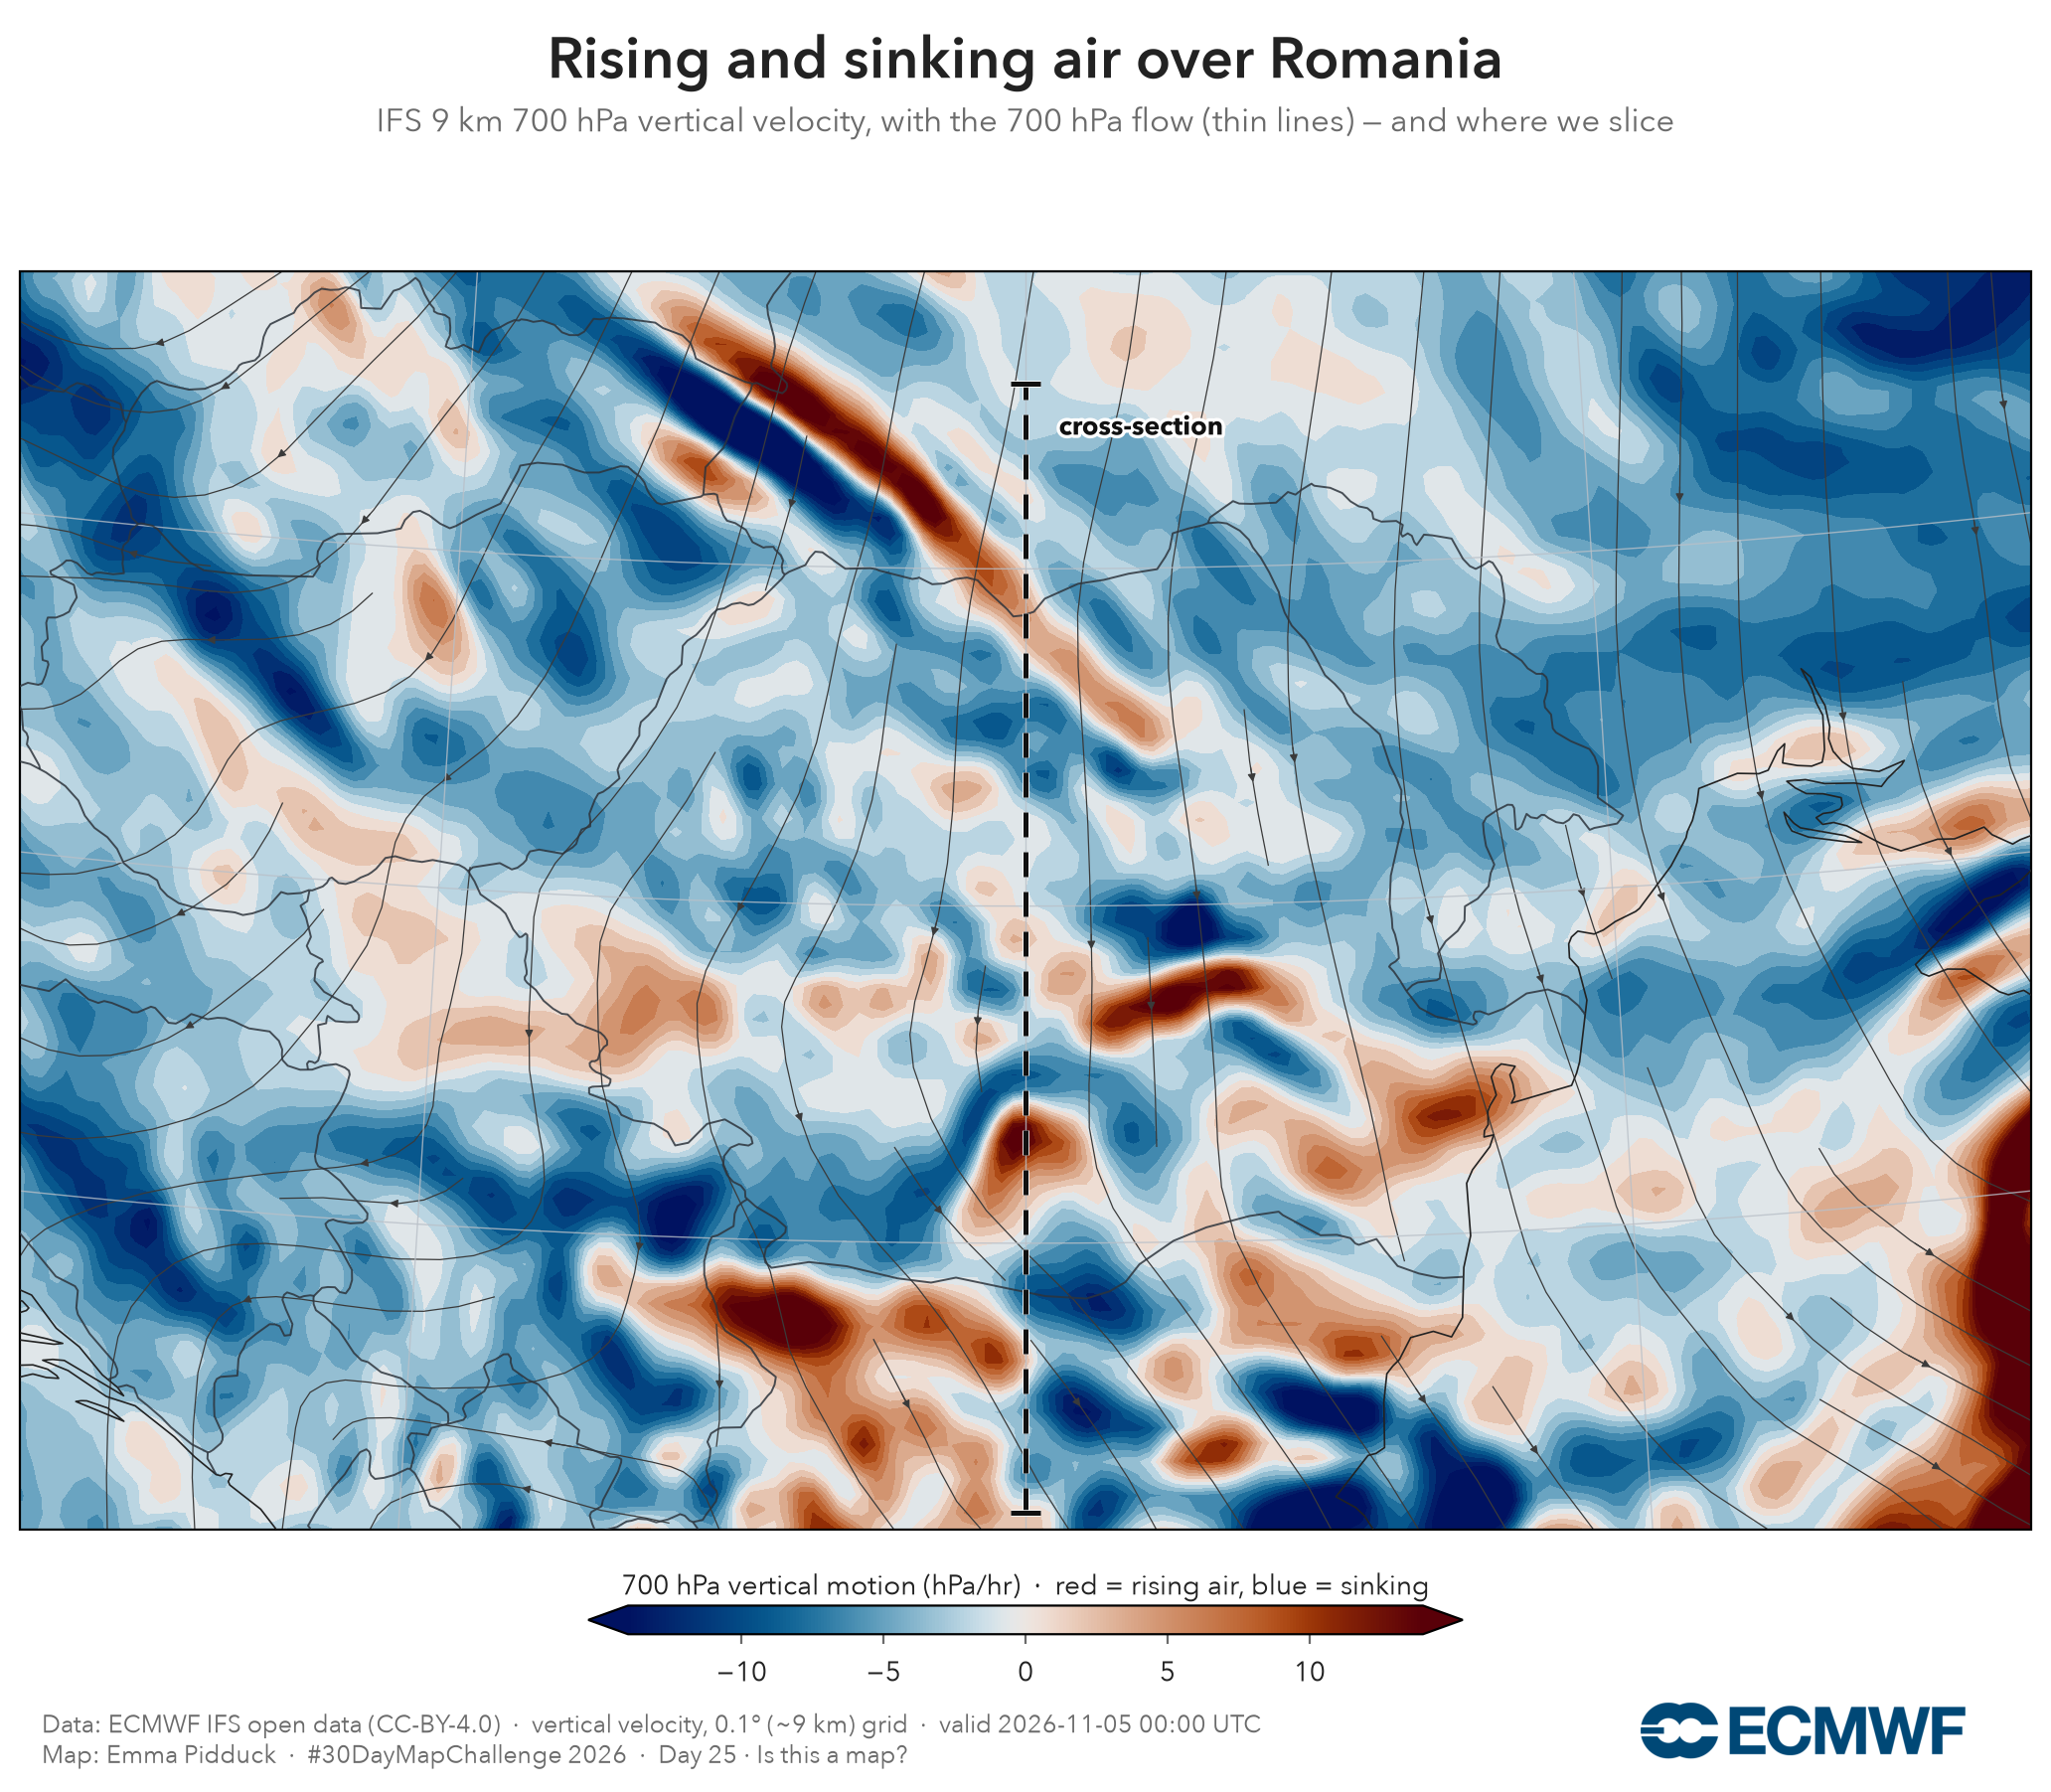

In [6]:
LVLMAP = 700
k = int(np.argmin(np.abs(lev - LVLMAP)))
mx = (lon >= REG[0]-2) & (lon <= REG[1]+2); my = (lat >= REG[2]-2) & (lat <= REG[3]+2)
mlon, mlat = lon[mx], lat[my]
asc = -W[k][np.ix_(my, mx)] * 36.0                # Pa/s -> hPa/hr, positive = ascent
asc_s = gaussian_filter(asc, 1.0) if gaussian_filter is not None else asc
u7, v7 = U[k][np.ix_(my, mx)], V[k][np.ix_(my, mx)]
LN0, LN1 = max(SECLAT0, REG[2]+0.4), min(SECLAT1, REG[3]-0.4)

fig = plt.figure(figsize=(11, 9), dpi=200); fig.patch.set_facecolor(BG)
proj = ccrs.LambertConformal(central_longitude=25, central_latitude=46, standard_parallels=(43, 49))
ax = fig.add_axes([0.04, 0.11, 0.92, 0.79], projection=proj)
ax.set_extent(REG, crs=ccrs.PlateCarree()); tp = dict(transform=ccrs.PlateCarree())
vmax = max(6.0, round(np.nanpercentile(np.abs(asc_s), 95)))
ax.contourf(mlon, mlat, asc_s, levels=np.linspace(-vmax, vmax, 21), cmap=cmc.vik,
            extend="both", zorder=0, **tp)
ax.streamplot(mlon, mlat, u7, v7, color="#3a3a3a", linewidth=0.45, density=0.8,
              arrowsize=0.6, transform=ccrs.PlateCarree(), zorder=1)
ax.add_feature(cfeature.COASTLINE.with_scale("50m"), edgecolor=INK, linewidth=0.6, zorder=3)
ax.add_feature(cfeature.BORDERS.with_scale("50m"), edgecolor="#2d343c", linewidth=0.7, alpha=0.85, zorder=3)
halo = [pe.withStroke(linewidth=2.4, foreground="white")]
ax.plot([SECLON, SECLON], [LN0, LN1], color="#111111", lw=1.8, ls=(0,(5,3)),
        transform=ccrs.PlateCarree(), zorder=4, path_effects=halo)
for la in (LN0, LN1):
    ax.plot(SECLON, la, marker="_", ms=11, mew=1.8, color="#111111",
            transform=ccrs.PlateCarree(), zorder=4, path_effects=halo)
ax.text(SECLON+0.3, LN1-0.15, "cross-section", color="#111111", fontsize=9.5, fontweight="bold",
        transform=ccrs.PlateCarree(), zorder=5, va="top", path_effects=halo)
ax.gridlines(draw_labels=False, xlocs=range(10,41,5), ylocs=range(40,51,2),
             color=GRID, linewidth=0.5, alpha=0.8, zorder=2)

cax = fig.add_axes([0.30, 0.095, 0.40, 0.016])
cb = fig.colorbar(mcm.ScalarMappable(norm=plt.Normalize(-vmax, vmax), cmap=cmc.vik),
                  cax=cax, orientation="horizontal", extend="both")
cb.set_label("700 hPa vertical motion (hPa/hr)  ·  red = rising air, blue = sinking", color=INK, fontsize=10)
cb.ax.xaxis.set_label_position("top")
cb.ax.xaxis.set_tick_params(color=MUT); plt.setp(plt.getp(cb.ax, "xticklabels"), color=INK)
fig.text(0.5, 0.965, "Rising and sinking air over Romania", ha="center", color=INK,
         fontsize=21, fontfamily=["Avenir Next Demi Bold","Arial","DejaVu Sans"])
fig.text(0.5, 0.935, "IFS 9 km 700 hPa vertical velocity, with the 700 hPa flow (thin lines) — and where we slice",
         ha="center", color=MUT, fontsize=12)
fig.text(0.05, 0.04, f"Data: ECMWF IFS open data (CC-BY-4.0)  ·  vertical velocity, 0.1° (~9 km) grid  ·  valid {VALID}",
         color=MUT, fontsize=9)
fig.text(0.05, 0.023, f"Map: {AUTHOR}  ·  #30DayMapChallenge 2026  ·  Day 25 · Is this a map?", color=MUT, fontsize=9)
if os.path.exists(logo):
    img = mpimg.imread(logo); ar = img.shape[1]/img.shape[0]
    h = 0.032; w = h*ar*(fig.get_figheight()/fig.get_figwidth())
    la = fig.add_axes([0.93-w, 0.025, w, h]); la.imshow(img); la.axis("off")
fig.savefig("day25_isthisamap_map.png", facecolor=BG, bbox_inches="tight"); plt.show()

## 2 · The slice — looking *edge-on*. Is **this** a map?

Now the vertical plane along 25°E. Latitude runs south→north across the bottom; pressure (height)
up the side. The **grey isentropes** show the atmosphere's layering — gently sloping where it's
stable, steepening at fronts and folding down at the tropopause near the **jet core** (purple).
The **green** line rings the moist, cloudy air. And the fill is the same quantity as the map —
rising and sinking air — but now you see it stacked through the whole depth of the sky.

It's a map of a *vertical* plane. Same data, same place, a different cut through it.

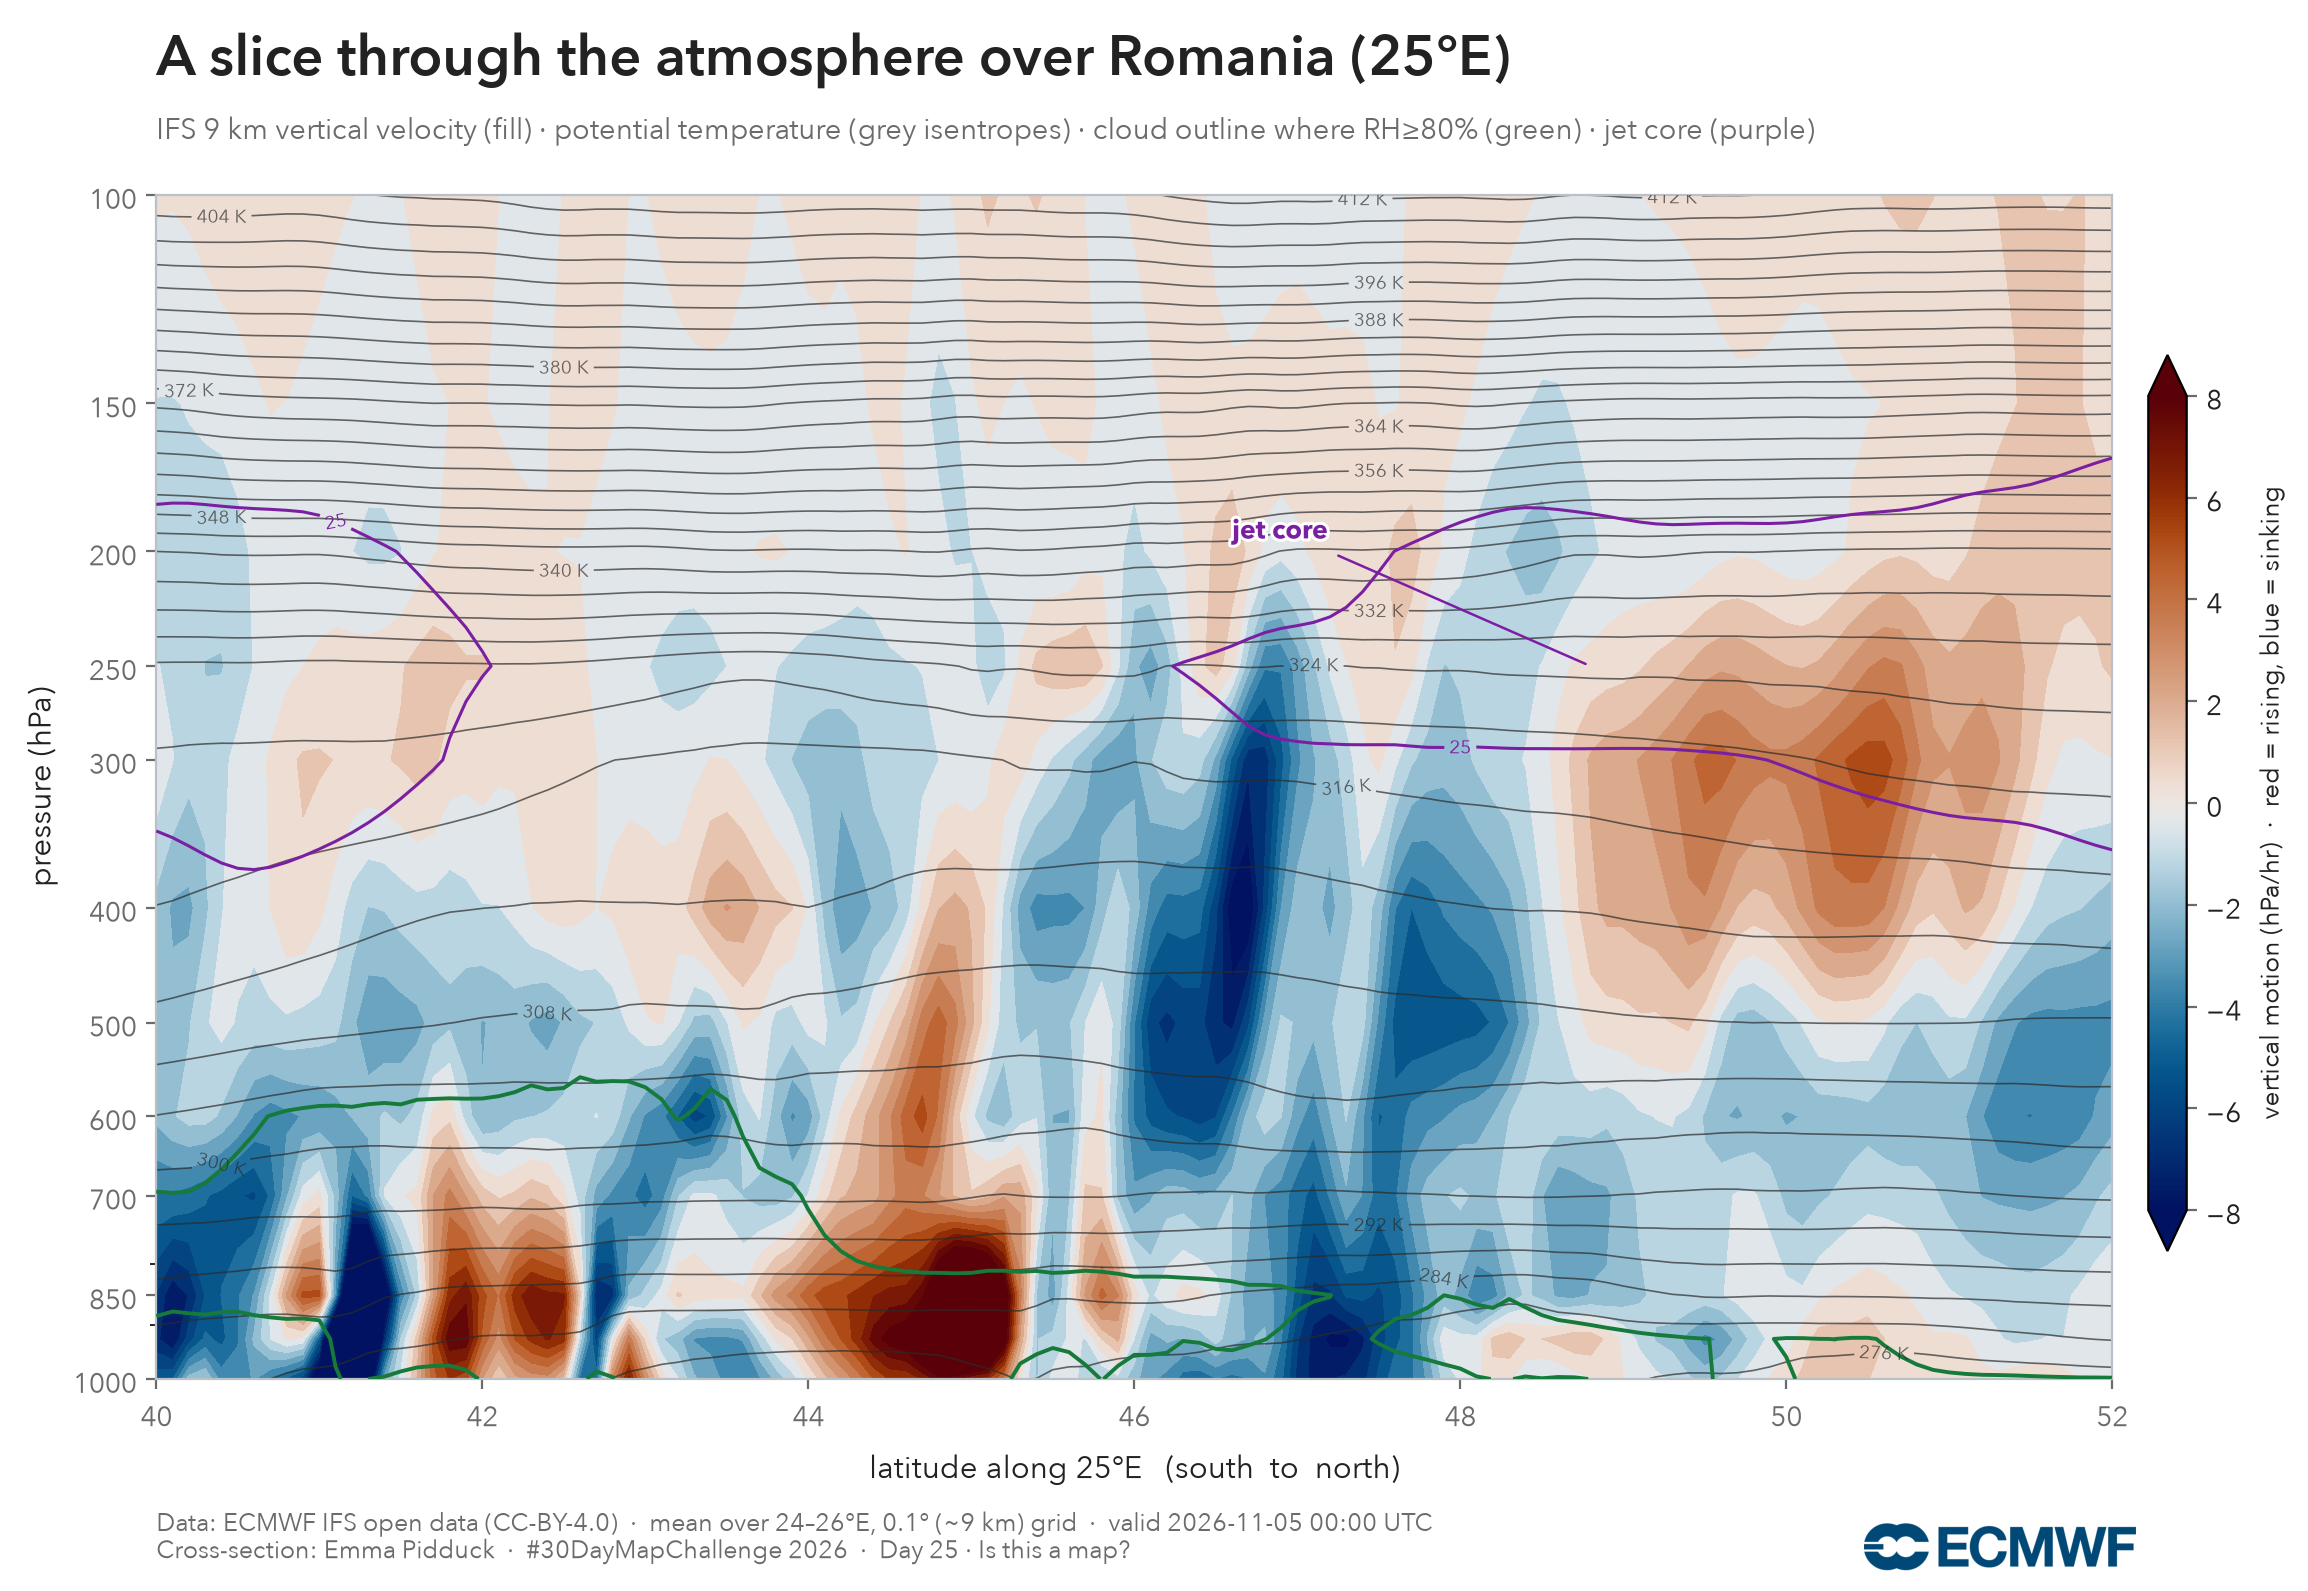

In [7]:
bandx = (lon >= SECLON-1) & (lon <= SECLON+1); bandy = (lat >= SECLAT0) & (lat <= SECLAT1)
slat = lat[bandy]
def band_mean(A): return np.nanmean(A[:, bandy][:, :, bandx], axis=2)   # (level, lat)
Ws, Us, Vs, Ts, Qs = (band_mean(a) for a in (W, U, V, T, Q))
P  = lev[:, None]
TH = Ts * (1000.0/P)**0.2857                                            # potential temperature (K)
asc2 = -Ws * 36.0                                                       # hPa/hr, ascent positive
if gaussian_filter is not None: asc2 = gaussian_filter(asc2, 0.7)       # light smooth for legibility
es = 6.112*np.exp(17.67*(Ts-273.15)/(Ts-29.65)); e = Qs*P/(0.622+0.378*Qs)
RH = np.clip(100*e/es, 0, 100)
spd = np.hypot(Us, Vs)
LA, PP = np.meshgrid(slat, lev)

fig2 = plt.figure(figsize=(12, 8), dpi=200); fig2.patch.set_facecolor(BG)
ax2 = fig2.add_axes([0.075, 0.14, 0.815, 0.74]); ax2.set_facecolor(BG)
vmax2 = max(3.0, round(np.nanpercentile(np.abs(asc2), 98)))
ax2.contourf(LA, PP, asc2, levels=np.linspace(-vmax2, vmax2, 21), cmap=cmc.vik, extend="both", zorder=0)
ct = ax2.contour(LA, PP, TH, levels=np.arange(260, 420, 4), colors="#2b2b2b", linewidths=0.6, alpha=0.7, zorder=2)
ax2.clabel(ct, ct.levels[::2], fmt="%d K", fontsize=7, colors="#2b2b2b")
ax2.contour(LA, PP, RH, levels=[80], colors="#157a3a", linewidths=1.4, zorder=3)
jc = ax2.contour(LA, PP, spd, levels=[25, 35, 45], colors="#7b1fa2", linewidths=1.1, zorder=4)
ax2.clabel(jc, fmt="%d", fontsize=7, colors="#7b1fa2")
ij, ii = np.unravel_index(np.nanargmax(spd), spd.shape)
ax2.annotate("jet core", xy=(slat[ii], lev[ij]), xytext=(slat[ii]-2.2, lev[ij]-55),
             color="#7b1fa2", fontsize=9.5, fontweight="bold",
             path_effects=[pe.withStroke(linewidth=2.2, foreground="white")], zorder=6,
             arrowprops=dict(arrowstyle="-", color="#7b1fa2", lw=0.9))
ax2.set_yscale("log"); ax2.set_ylim(1000, 100)
ax2.yaxis.set_major_formatter(ScalarFormatter()); ax2.yaxis.set_minor_formatter(NullFormatter())
ax2.set_yticks([1000,850,700,600,500,400,300,250,200,150,100])
ax2.set_yticklabels([1000,850,700,600,500,400,300,250,200,150,100])
ax2.set_xlim(SECLAT0, SECLAT1)
ax2.set_xlabel("latitude along 25°E   (south  to  north)", color=INK, fontsize=11)
ax2.set_ylabel("pressure (hPa)", color=INK, fontsize=11)
ax2.tick_params(colors=MUT)
for s in ax2.spines.values(): s.set_color(GRID)
cax2 = fig2.add_axes([0.905, 0.22, 0.016, 0.56])
cb2 = fig2.colorbar(mcm.ScalarMappable(norm=plt.Normalize(-vmax2, vmax2), cmap=cmc.vik),
                    cax=cax2, orientation="vertical", extend="both")
cb2.set_label("vertical motion (hPa/hr)  ·  red = rising, blue = sinking", color=INK, fontsize=9.5)
cb2.ax.yaxis.set_tick_params(color=MUT); plt.setp(plt.getp(cb2.ax, "yticklabels"), color=INK)
fig2.text(0.075, 0.955, "A slice through the atmosphere over Romania (25°E)", color=INK,
          fontsize=20, fontfamily=["Avenir Next Demi Bold","Arial","DejaVu Sans"])
fig2.text(0.075, 0.915, "IFS 9 km vertical velocity (fill) · potential temperature (grey isentropes) · "
          "cloud outline where RH≥80% (green) · jet core (purple)", color=MUT, fontsize=10.5)
fig2.text(0.075, 0.045, f"Data: ECMWF IFS open data (CC-BY-4.0)  ·  mean over 24–26°E, 0.1° (~9 km) grid  ·  valid {VALID}",
          color=MUT, fontsize=9)
fig2.text(0.075, 0.028, f"Cross-section: {AUTHOR}  ·  #30DayMapChallenge 2026  ·  Day 25 · Is this a map?",
          color=MUT, fontsize=9)
if os.path.exists(logo):
    img = mpimg.imread(logo); ar = img.shape[1]/img.shape[0]
    h = 0.03; w = h*ar*(fig2.get_figheight()/fig2.get_figwidth())
    la2 = fig2.add_axes([0.9-w, 0.02, w, h]); la2.imshow(img); la2.axis("off")
fig2.savefig("day25_isthisamap_section.png", facecolor=BG, bbox_inches="tight"); plt.show()

## Note — so, is it a map?

A map is a scaled representation of located things on a chosen surface. The usual surface is the
ground, seen from above. But nothing says the surface has to be horizontal: a **cross-section** is
a map of a *vertical* plane through the atmosphere, and meteorologists read them every day — they
are how you see fronts, the tropopause, the jet's transverse circulation, and exactly the rising
and sinking air that the top map only hints at.

So both pictures above are maps of the same instant over Romania. One chose the horizontal cut we
expect; the other chose a vertical one. The theme's question answers itself: *yes* — and noticing
*why* is the fun of it.

*Part of a #30DayMapChallenge 2026 series built on ECMWF (and MeteoSwiss) open data.
Day 2 is Lines — the jet stream; Day 22 is Projections — the distortion every flat map makes.*